# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?

**R1.** CLIP stands for Contrastive Language–Image Pre-training. It is a model that learns relationships between image and text

**Q2.** What are its two main components?  
**R2.** An Image Encoder and a Text Encoder

**Q3.** What is the role of `CLIPProcessor`?  
**R3.** It preprocesses images and tokenizes text to prepare inputs for CLIP

**Q4.** What is the role of `CLIPModel`?

**R4.** It encodes images and text and computes similarity scores between them



In [11]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [12]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**R5.** The image size is 1800 × 1200 pixels (width × height).
**Q6.** What type of data is stored in the PIL image object?
**R6.** The PIL image object stores pixel data in RGB format (Red, Green, Blue).

In [15]:
from google.colab import files

uploaded = files.upload()

Saving image.jpeg to image.jpeg


Image size: (1800, 1200)
Image mode: RGB


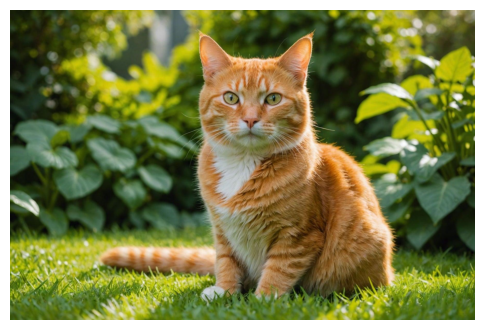

In [16]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "image.jpeg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**R7.** The description "a photo of a cat" has the highest probability, with a score of 0.9913 (99.13%)
**Q8.** Is it compatible with the actual image?  
**R8.** yes

**Q9.** Why can CLIP compare an image with a sentence?  
**R9.** CLIP uses two encoders, an image encoder and a text encoder, to transform images and text into embeddings in a shared vector space. It then calculates their similarity
**Q10.** What does `softmax()` do?
**R10.** Softmax converts the similarity scores into a probability distribution over the candidate descriptions. All probabilities sum to 1

In [17]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9913
a photo of a dog                   : 0.0047
a photo of a car                   : 0.0000
a photo of a horse                 : 0.0004
a photo of a person                : 0.0035


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**R11.** Zero-shot classification is the ability of a pretrained model to classify images into predefined categories without additional training on labeled examples of those categories
**Q12.** Why is it not necessary to train a new classifier?  
**R12.** Because CLIP has already learned relationships between images and text during pretraining. It can compare image embeddings with text embeddings to identify the most relevant class without additional training

**Q13.** What happens if the correct class is not included in the candidate classes?

**R13.** CLIP selects the most similar class among the available candidates, even if the prediction is incorrect

In [18]:
# STUDENT TASK
def classify_image(image, classes):

    # Step 1: Create text descriptions
    texts = [f"a photo of a {c}" for c in classes]

    # Step 2: Preprocess image and text
    inputs = processor(
        text=texts,
        images=image,
        return_tensors="pt",
        padding=True
    )

    # Step 3: Move inputs to device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Step 4: Run CLIP
    with torch.no_grad():
        outputs = model(**inputs)

    # Step 5: Convert scores to probabilities
    probs = outputs.logits_per_image.softmax(dim=1)[0]

    # Step 6: Find the highest probability
    predicted_index = probs.argmax().item()

    # Step 7: Return prediction and probability
    prediction = classes[predicted_index]
    probability = probs[predicted_index].item()

    return prediction, probability

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

# Uncomment after implementing the function:
prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

classes = ["dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)

print("Prediction:", prediction)
print("Probability:", probability)

Prediction: cat
Probability: 0.9944990277290344
Prediction: dog
Probability: 0.8647969365119934


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**R14.** accuracy is 100%
**Q15.** Which images are incorrectly classified?  
**R15.** No images were incorrectly classified
**Q16.** Give at least two possible reasons for the errors.
**R16.** Visual ambiguity, Text descriptions
Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [12]:
uploaded = files.upload()

Saving airplane.jpeg to airplane.jpeg
Saving bird1.jpeg to bird1.jpeg
Saving bird2.jpeg to bird2.jpeg
Saving car1.jpeg to car1.jpeg
Saving car2.jpeg to car2.jpeg
Saving cat1.jpeg to cat1.jpeg
Saving dog1.jpeg to dog1.jpeg
Saving dog2.jpeg to dog2.jpeg
Saving horse1.jpeg to horse1.jpeg


In [16]:
# STUDENT TASK
dataset = [
    ("cat1.jpeg", "cat"),
    ("image.jpeg", "cat"),
    ("dog1.jpeg", "dog"),
    ("dog2.jpeg", "dog"),
    ("car1.jpeg", "car"),
    ("car2.jpeg", "car"),
    ("horse1.jpeg", "horse"),
    ("bird2.jpeg", "bird"),
    ("bird1.jpeg", "bird"),
    ("airplane.jpeg", "airplane")
]

# Implement the evaluation after preparing your images.

import pandas as pd
from PIL import Image

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

results = []

for image_path, actual_class in dataset:

    # Load image
    img = Image.open(image_path).convert("RGB")

    # Predict class
    prediction, probability = classify_image(img, classes)

    # Check if prediction is correct
    correct = prediction == actual_class

    # Store results
    results.append({
        "Image": image_path,
        "Actual": actual_class,
        "Predicted": prediction,
        "Probability": probability,
        "Correct": correct
    })

df = pd.DataFrame(results)

print(df.to_string(index=False))

accuracy = df["Correct"].mean()

print(f"Accuracy: {accuracy:.2%}")

        Image   Actual Predicted  Probability  Correct
    cat1.jpeg      cat       cat     0.994352     True
   image.jpeg      cat       cat     0.994499     True
    dog1.jpeg      dog       dog     0.990371     True
    dog2.jpeg      dog       dog     0.997687     True
    car1.jpeg      car       car     0.992350     True
    car2.jpeg      car       car     0.996945     True
  horse1.jpeg    horse     horse     0.999743     True
   bird2.jpeg     bird      bird     0.998997     True
   bird1.jpeg     bird      bird     0.998888     True
airplane.jpeg airplane  airplane     0.997213     True
Accuracy: 100.00%


In [17]:
errors = df[df["Correct"] == False]

print("Incorrectly classified images:")
print(errors.to_string(index=False))

Incorrectly classified images:
Empty DataFrame
Columns: [Image, Actual, Predicted, Probability, Correct]
Index: []


## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**R17.** No

**Q18.** Which prompt gives the highest score?
**R18.** a photograph showing a cat   
**Q19.** What does this demonstrate about prompt formulation?
**R19.** This experiment demonstrates that prompt formulation influences CLIP's image-text similarity scores. Even small changes in wording can affect the results

In [18]:
# Step 1: Define different prompts
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

# Step 2: Preprocess image and prompts
inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
)

# Step 3: Move inputs to device
inputs = {k: v.to(device) for k, v in inputs.items()}

# Step 4: Run CLIP
with torch.no_grad():
    outputs = model(**inputs)

# Step 5: Get similarity scores
scores = outputs.logits_per_image[0].cpu()

# Step 6: Display results
for prompt, score in zip(prompts, scores):
    print(f"{prompt:40s}: {score.item():.4f}")

a cat                                   : 27.3570
a photo of a cat                        : 29.2316
a photograph showing a cat              : 30.1490
an image containing a cat               : 28.1414
a domestic animal called a cat          : 28.9144


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**R20.** CLIP retrieved five images: a flying bird, a mountain landscape, a running horse, a city skyline, and another running horse. The flying bird ranked first with a similarity score of 0.2656.
**Q21.** Is it semantically relevant?
**R21.** The first image is highly relevant because it shows an orange car, matching both the object and the color in the query. The second image is partially relevant because it shows a car of a different color. The remaining images are less relevant.
**Q22.** Why does this method not require image labels?  
**R22.** This method does not require image labels because CLIP uses pretrained image and text encoders to represent images and text in the same embedding space.
**Q23.** Give one real-world application of semantic image retrieval.
**R23.** e-commerce product search, where customers can find products using natural language descriptions

In [19]:
import os
IMAGE_DIR = "images"
os.makedirs(IMAGE_DIR, exist_ok=True)
uploaded = files.upload()

# Move uploaded files into images folder
for filename, content in uploaded.items():
    with open(os.path.join(IMAGE_DIR, filename), "wb") as f:
        f.write(content)

print("Uploaded images:", len(uploaded))


Saving 1.jpeg to 1.jpeg
Saving 2.jpeg to 2.jpeg
Saving 3.jpeg to 3.jpeg
Saving 4.jpg to 4.jpg
Saving 5.jpeg to 5 (1).jpeg
Saving 6.jpg to 6.jpg
Saving 7.jpeg to 7.jpeg
Saving 8.jpeg to 8.jpeg
Saving 9.jpg to 9.jpg
Saving 10.jpg to 10.jpg
Saving 11.jpeg to 11.jpeg
Saving 12.jpeg to 12.jpeg
Saving 13.jpeg to 13.jpeg
Saving 14.jpeg to 14.jpeg
Saving 15.jpeg to 15.jpeg
Saving 16.jpeg to 16.jpeg
Saving 17.jpeg to 17 (1).jpeg
Saving 18.jpg to 18.jpg
Saving 19.jpeg to 19.jpeg
Saving 20.jpeg to 20.jpeg
Uploaded images: 20


In [20]:
from PIL import Image
import os

image_paths = []

for filename in sorted(os.listdir(IMAGE_DIR)):

    if filename.lower().endswith(
        (".jpg", ".jpeg", ".png", ".webp")
    ):
        image_paths.append(
            os.path.join(IMAGE_DIR, filename)
        )

print("Number of images:", len(image_paths))
print(image_paths)

Number of images: 20
['images/1.jpeg', 'images/10.jpg', 'images/11.jpeg', 'images/12.jpeg', 'images/13.jpeg', 'images/14.jpeg', 'images/15.jpeg', 'images/16.jpeg', 'images/17.jpeg', 'images/18.jpg', 'images/19.jpeg', 'images/2.jpeg', 'images/20.jpeg', 'images/3.jpeg', 'images/4.jpg', 'images/5.jpeg', 'images/6.jpg', 'images/7.jpeg', 'images/8.jpeg', 'images/9.jpg']


In [22]:
import torch
import torch.nn.functional as F
from PIL import Image

image_embeddings = []

model.eval()

for image_path in image_paths:

    # Load image
    img = Image.open(image_path).convert("RGB")

    # Preprocess image
    inputs = processor(
        images=img,
        return_tensors="pt"
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Extract image features
    with torch.no_grad():
        outputs = model.vision_model(
            pixel_values=inputs["pixel_values"]
        )

        embedding = model.visual_projection(
            outputs.pooler_output
        )

    # Normalize embedding
    embedding = F.normalize(embedding, p=2, dim=-1)

    # Store embedding
    image_embeddings.append(embedding.cpu())

In [23]:
image_embeddings = torch.cat(image_embeddings, dim=0)

print("Embeddings shape:", image_embeddings.shape)
print("First embedding norm:", torch.norm(image_embeddings[0]).item())

Embeddings shape: torch.Size([20, 512])
First embedding norm: 0.9999998807907104


In [24]:
torch.save({
    "image_paths": image_paths,
    "embeddings": image_embeddings
}, "clip_image_database.pt")

print("Image database saved successfully!")

Image database saved successfully!


In [31]:
# STUDENT TASK
# 1. Put your images in IMAGE_DIR.

# 2. Compute image embeddings.
# 3. Compute the query embedding.
# 4. Calculate cosine similarity.
# 5. Display Top-5 images.

query = "an orange car"

In [32]:
import torch
import torch.nn.functional as F

# Preprocess text
text_inputs = processor(
    text=[query],
    return_tensors="pt",
    padding=True
)

text_inputs = {
    k: v.to(device)
    for k, v in text_inputs.items()
}

# Extract text features
with torch.no_grad():
    text_outputs = model.text_model(
        input_ids=text_inputs["input_ids"],
        attention_mask=text_inputs["attention_mask"]
    )

    text_embedding = model.text_projection(
        text_outputs.pooler_output
    )

# Normalize text embedding
text_embedding = F.normalize(
    text_embedding,
    p=2,
    dim=-1
)

print("Text embedding shape:", text_embedding.shape)

Text embedding shape: torch.Size([1, 512])


In [33]:
# Move text embedding to CPU
text_embedding = text_embedding.cpu()

# Compute cosine similarities
similarities = image_embeddings @ text_embedding.T

print("Similarities shape:", similarities.shape)

Similarities shape: torch.Size([20, 1])


In [34]:
# Convert similarities to 1D
scores = similarities.squeeze(1)

# Retrieve top 5
top_scores, top_indices = torch.topk(
    scores,
    k=5
)

# Print results
for rank, (score, idx) in enumerate(
    zip(top_scores, top_indices),
    start=1
):
    print(
        f"{rank}. {image_paths[idx.item()]} "
        f"- Similarity: {score.item():.4f}"
    )

1. images/7.jpeg - Similarity: 0.2710
2. images/8.jpeg - Similarity: 0.1948
3. images/20.jpeg - Similarity: 0.1915
4. images/10.jpg - Similarity: 0.1867
5. images/19.jpeg - Similarity: 0.1841


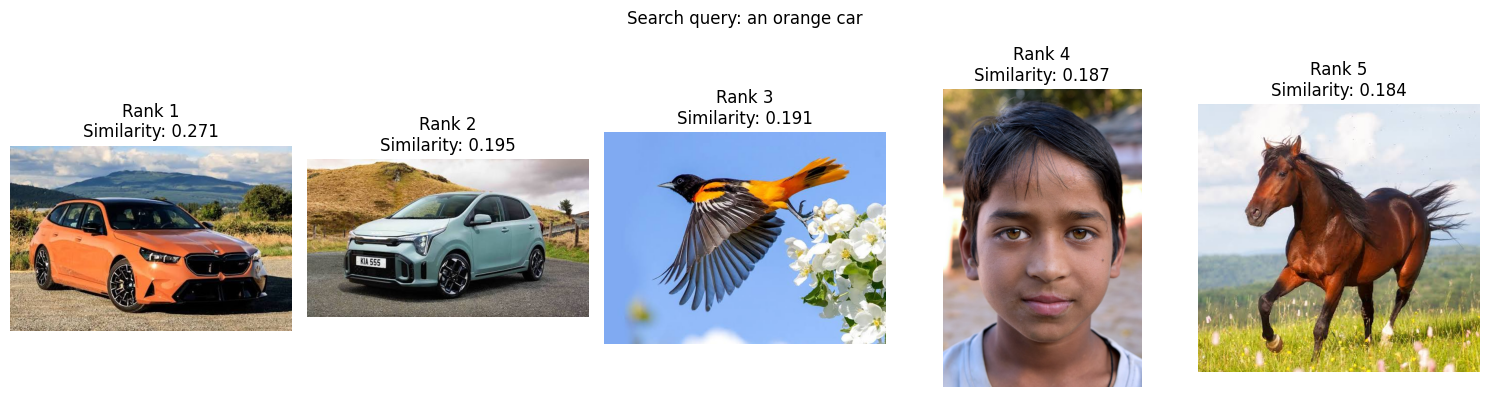

In [35]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(15, 4))

for i, (score, idx) in enumerate(
    zip(top_scores, top_indices)
):
    image_path = image_paths[idx.item()]
    img = Image.open(image_path).convert("RGB")

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(
        f"Rank {i+1}\nSimilarity: {score.item():.3f}"
    )
    plt.axis("off")

plt.suptitle(f"Search query: {query}")
plt.tight_layout()
plt.show()

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**R24.** The vision encoder extracts visual features from the input image and converts them into numerical representations that capture its visual content
**Q25.** Why is a projection layer required?  
**R25.** The projection layer maps the visual features into the embedding space expected by the language model, allowing it to process visual information together with text
**Q26.** What is the role of the language model?
**R26.** The language model processes the visual representations and the user's text prompt to generate meaningful natural language responses about the image

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [1]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [2]:
!pip install -q -U transformers accelerate bitsandbytes pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 116.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 119.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [3]:
import torch
from transformers import (
    AutoProcessor,
    LlavaForConditionalGeneration,
    BitsAndBytesConfig
)

MODEL_ID = "llava-hf/llava-1.5-7b-hf"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4"
)

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)

llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=torch.float16
)

llava.eval()

print("LLaVA loaded successfully!")

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

LLaVA loaded successfully!


Saving 17.jpeg to 17.jpeg


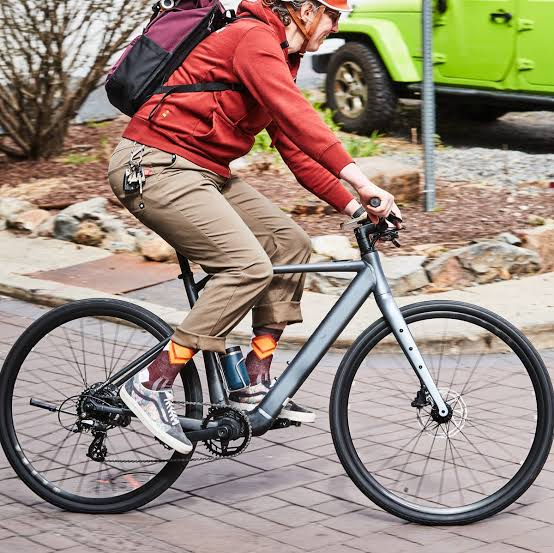

In [6]:
from google.colab import files
from PIL import Image
import io

uploaded = files.upload()

filename = next(iter(uploaded))
image_llava = Image.open(
    io.BytesIO(uploaded[filename])
).convert("RGB")

display(image_llava)

In [7]:
question = "What is happening in this image?"

prompt = f"USER: <image>\n{question}\nASSISTANT:"

inputs = processor_llava(
    images=image_llava,
    text=prompt,
    return_tensors="pt"
).to("cuda")

with torch.inference_mode():
    output = llava.generate(
        **inputs,
        max_new_tokens=150,
        do_sample=False
    )

answer = processor_llava.decode(
    output[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("Question:", question)
print("Answer:", answer)

Question: What is happening in this image?
Answer: In the image, a person is riding a bicycle down a street. The cyclist is wearing a backpack and has a helmet on for safety. The street is lined with parked cars, and there is a truck parked further down the road. The cyclist is navigating through the parked vehicles, showcasing their skill and awareness of the surroundings.


In [8]:
questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

answers = []

for question in questions:
    prompt = f"USER: <image>\n{question}\nASSISTANT:"

    inputs = processor_llava(
        images=image_llava,
        text=prompt,
        return_tensors="pt"
    ).to("cuda")

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False
        )

    answer = processor_llava.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    answers.append({
        "Question": question,
        "Answer": answer
    })

import pandas as pd

df_answers = pd.DataFrame(answers)
display(df_answers)

,Question,Answer
0,What is happening in this image?,"In the image, a person is riding a bicycle dow..."
1,How many people are visible?,"There is only one person visible in the image,..."
2,What objects can you identify?,"In the image, you can identify a bicycle, a pe..."
3,Describe the image in detail.,The image features a person riding a bicycle d...


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**R27.** The VQA accuracy was 88%
**Q28.** Which types of questions are difficult for LLaVA?
**R28.** LLaVA successfully identified the main subjects and counted people, but made errors in detailed visual descriptions, particularly object attributes such as colors.

In [20]:
import os

image_files = sorted([
    os.path.join("images", f)
    for f in os.listdir("images")
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Available images:", len(image_files))

for path in image_files:
    print(path)

Available images: 20
images/1.jpeg
images/10.jpg
images/11.jpeg
images/12.jpeg
images/13.jpeg
images/14.jpeg
images/15.jpeg
images/16.jpeg
images/17 (1).jpeg
images/18.jpg
images/19.jpeg
images/2.jpeg
images/20.jpeg
images/3.jpeg
images/4.jpg
images/5 (1).jpeg
images/6.jpg
images/7.jpeg
images/8.jpeg
images/9.jpg


In [24]:
selected_images = [
    "images/1.jpeg",
    "images/2.jpeg",
    "images/10.jpg",
    "images/15.jpeg",
    "images/20.jpeg"
]

for path in selected_images:
    assert os.path.isfile(path), f"Image not found: {path}"

In [25]:
questions = [
    "What is happening in this image?",
    "How many people are visible in the image?",
    "What objects can you identify?",
    "What is the main subject of the image?",
    "Describe the background of the image."
]

In [26]:


def ask_llava(image, question):

    prompt = f"USER: <image>\n{question}\nASSISTANT:"

    inputs = processor_llava(
        images=image,
        text=prompt,
        return_tensors="pt"
    ).to("cuda")

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False
        )

    answer = processor_llava.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return answer.strip()

In [27]:


results = []

for image_path in selected_images:

    image = Image.open(image_path).convert("RGB")

    print(f"\nProcessing: {image_path}")

    for question in questions:

        answer = ask_llava(image, question)

        results.append({
            "Image": image_path,
            "Question": question,
            "Answer": answer
        })

        print("Q:", question)
        print("A:", answer)
        print("-" * 40)

df_vqa = pd.DataFrame(results)

display(df_vqa)


Processing: images/1.jpeg
Q: What is happening in this image?
A: In the image, a small white rabbit is standing on a patch of grass, surrounded by green plants. The rabbit appears to be looking at the camera, possibly posing for a picture. The scene is set in a forest-like environment, with the rabbit being the main focus of the image.
----------------------------------------
Q: How many people are visible in the image?
A: There are no people visible in the image. The focus is on the small white rabbit.
----------------------------------------
Q: What objects can you identify?
A: In the image, you can identify a small white rabbit standing on a patch of grass, surrounded by green plants. The rabbit appears to be looking at the camera, and its ears are perked up. The scene is set in a wooded area, with the rabbit being the main subject of the image.
----------------------------------------
Q: What is the main subject of the image?
A: The main subject of the image is a small white rabbi

,Image,Question,Answer
0,images/1.jpeg,What is happening in this image?,"In the image, a small white rabbit is standing..."
1,images/1.jpeg,How many people are visible in the image?,There are no people visible in the image. The ...
2,images/1.jpeg,What objects can you identify?,"In the image, you can identify a small white r..."
3,images/1.jpeg,What is the main subject of the image?,The main subject of the image is a small white...
4,images/1.jpeg,Describe the background of the image.,The background of the image features a forest ...
5,images/2.jpeg,What is happening in this image?,"In the image, a white wolf is standing in a gr..."
6,images/2.jpeg,How many people are visible in the image?,There are no people visible in the image. The ...
7,images/2.jpeg,What objects can you identify?,"In the image, you can identify a white wolf st..."
8,images/2.jpeg,What is the main subject of the image?,The main subject of the image is a white wolf ...
9,images/2.jpeg,Describe the background of the image.,"In the background of the image, there is a roc..."


In [31]:
df_vqa["Correct"] = 1

df_vqa.loc[10, "Correct"] = 0

df_vqa.loc[23, "Correct"] = 0


df_vqa.loc[24, "Correct"] = 0


display(df_vqa)

,Image,Question,Answer,Correct
0,images/1.jpeg,What is happening in this image?,"In the image, a small white rabbit is standing...",1
1,images/1.jpeg,How many people are visible in the image?,There are no people visible in the image. The ...,1
2,images/1.jpeg,What objects can you identify?,"In the image, you can identify a small white r...",1
3,images/1.jpeg,What is the main subject of the image?,The main subject of the image is a small white...,1
4,images/1.jpeg,Describe the background of the image.,The background of the image features a forest ...,1
5,images/2.jpeg,What is happening in this image?,"In the image, a white wolf is standing in a gr...",1
6,images/2.jpeg,How many people are visible in the image?,There are no people visible in the image. The ...,1
7,images/2.jpeg,What objects can you identify?,"In the image, you can identify a white wolf st...",1
8,images/2.jpeg,What is the main subject of the image?,The main subject of the image is a white wolf ...,1
9,images/2.jpeg,Describe the background of the image.,"In the background of the image, there is a roc...",1


In [32]:
evaluated = df_vqa.dropna(subset=["Correct"]).copy()

evaluated["Correct"] = evaluated["Correct"].astype(int)

if len(evaluated) > 0:
    accuracy = evaluated["Correct"].mean() * 100
    print(f"VQA Accuracy: {accuracy:.2f}%")
else:
    print("No answers evaluated yet.")

VQA Accuracy: 88.00%


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?
**R29.** No, the bicycle does not exist in the image. The image shows a small white rabbit in a natural environment
**Q30.** Did LLaVA invent information?  
**R30.** Yes. Although LLaVA initially recognized that there was no bicycle, it later invented its color and location
**Q31.** What is a visual hallucination?  
**R31.** A visual hallucination occurs when a multimodal model generates information about objects or details that are not actually present in the input image
**Q32.** Why can a multimodal model hallucinate?
Multimodal models can hallucinate because they rely on learned patterns and may be influenced by misleading questions. They sometimes generate plausible answers instead of verifying whether the described objects actually exist

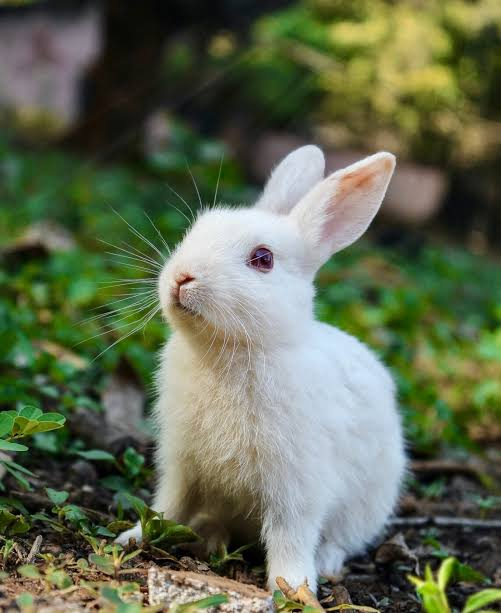

In [33]:
image_hallucination = Image.open("images/1.jpeg").convert("RGB")

display(image_hallucination)

In [34]:
questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]

results = []

for question in questions:
    answer = ask_llava(image_hallucination, question)

    results.append({
        "Question": question,
        "LLaVA Answer": answer
    })


df_hallucination = pd.DataFrame(results)
display(df_hallucination)

,Question,LLaVA Answer
0,Is there a bicycle in this image?,"No, there is no bicycle in this image. The ima..."
1,What color is the bicycle?,The bicycle is white.
2,Where is the bicycle located?,"The bicycle is located in the woods, surrounde..."


# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**R33.** CLIP is better suited to zero-shot image classification
**Q34.** Which model is better for image description?  
**R34.** LLaVA is better for image description
**Q35.** Which model is better for visual question answering?  
**R35.** LLaVA is better for visual question answering (VQA) because it can understand images and generate answers to questions about their content
**Q36.** Explain the fundamental difference between CLIP and LLaVA.
**R36.** CLIP is a contrastive model that learns shared image-text representations to measure similarity. LLaVA is a generative multimodal model that combines a vision encoder with a large language model to understand images and generate natural-language responses.

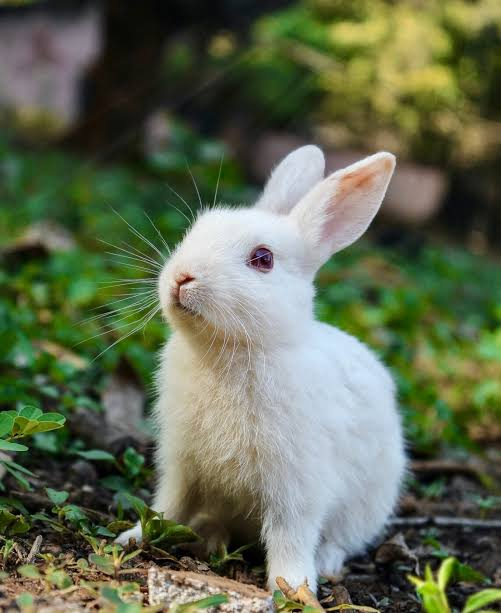

In [44]:
image_compare = Image.open("images/1.jpeg").convert("RGB")

display(image_compare)

In [45]:
import torch
import torch.nn.functional as F
import pandas as pd

clip_prompts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a horse"
]

inputs = processor(
    text=clip_prompts,
    images=image_compare,
    return_tensors="pt",
    padding=True
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)
    probabilities = outputs.logits_per_image.softmax(dim=1)[0]

df_clip = pd.DataFrame({
    "Description": clip_prompts,
    "Probability": probabilities.cpu().numpy()
})

display(df_clip)

best_index = probabilities.argmax().item()
print("CLIP prediction:", clip_prompts[best_index])

,Description,Probability
0,a photo of a cat,0.539332
1,a photo of a dog,0.406834
2,a photo of a horse,0.053834


CLIP prediction: a photo of a cat


In [46]:
question = "What animal is present in the image? Describe its appearance."

llava_answer = ask_llava(image_compare, question)

print("LLaVA Answer:")
print(llava_answer)

LLaVA Answer:
A white rabbit is present in the image. It has long ears and is standing on a patch of grass.


# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [47]:
def multimodal_image_assistant(image_path, question):

    # Load the image
    image = Image.open(image_path).convert("RGB")

    print("Selected image:")
    display(image)

    print("Question:", question)

    # Generate the answer using LLaVA
    answer = ask_llava(image, question)

    print("Assistant:", answer)

    return answer

Selected image:


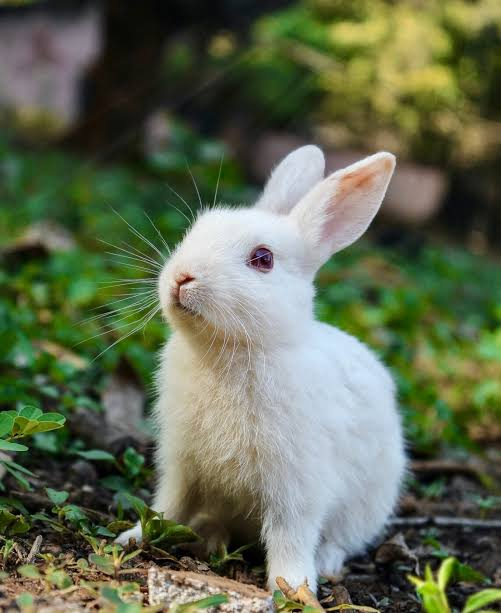

Question: What animal is in this image? Describe its appearance.
Assistant: The image features a small white rabbit. The rabbit has a fluffy appearance, with its ears perked up and its whiskers sticking out. It is standing in a grassy area, surrounded by greenery.


In [48]:
answer1 = multimodal_image_assistant(
    "images/1.jpeg",
    "What animal is in this image? Describe its appearance."
)

Selected image:


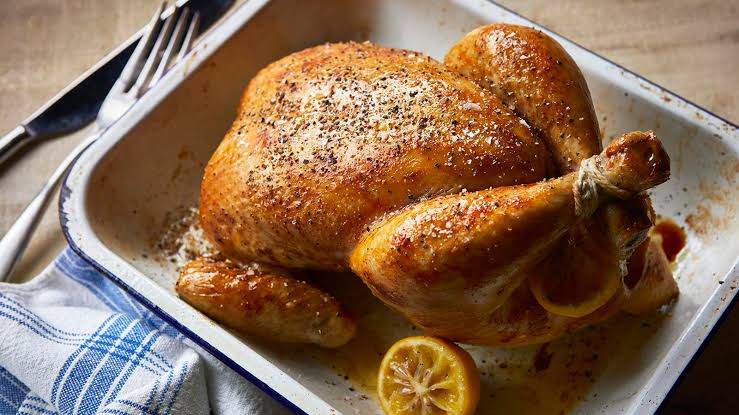

Question: What food is shown in this image?
Assistant: The image shows a cooked chicken, which is placed in a pan.


In [49]:
answer2 = multimodal_image_assistant(
    "images/15.jpeg",
    "What food is shown in this image?"
)

Selected image:


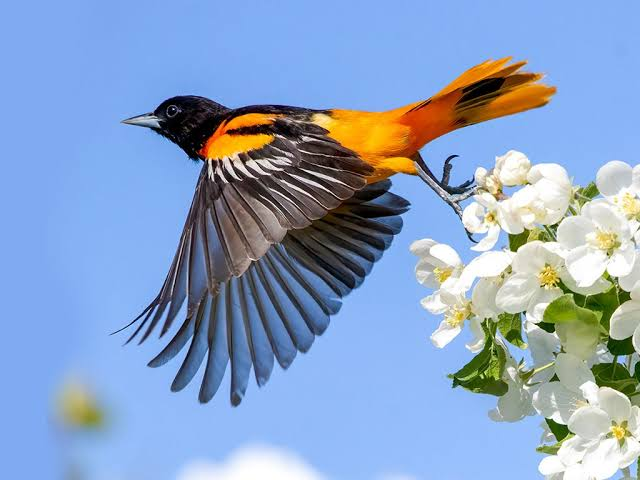

Question: What is the bird doing in this image?
Assistant: The bird is flying through the air, hovering over a flower-covered tree branch.


In [50]:
answer3 = multimodal_image_assistant(
    "images/20.jpeg",
    "What is the bird doing in this image?"
)

In [51]:
import os
import ipywidgets as widgets
from IPython.display import display, clear_output

image_files = sorted([
    os.path.join("images", f)
    for f in os.listdir("images")
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

image_selector = widgets.Dropdown(
    options=image_files,
    description="Image:"
)

question_input = widgets.Text(
    value="What is happening in this image?",
    description="Question:",
    layout=widgets.Layout(width="650px")
)

ask_button = widgets.Button(
    description="Ask LLaVA",
    button_style="success"
)

output_area = widgets.Output()

def on_ask_clicked(button):
    with output_area:
        clear_output(wait=True)

        multimodal_image_assistant(
            image_selector.value,
            question_input.value
        )

ask_button.on_click(on_ask_clicked)

display(image_selector, question_input, ask_button, output_area)

Dropdown(description='Image:', options=('images/1.jpeg', 'images/10.jpg', 'images/11.jpeg', 'images/12.jpeg', …

Text(value='What is happening in this image?', description='Question:', layout=Layout(width='650px'))

Button(button_style='success', description='Ask LLaVA', style=ButtonStyle())

Output()

## Short conclusion

This lab explored multimodal AI using CLIP and LLaVA. CLIP was used for image classification and retrieval, while LLaVA was used for image description and visual question answering. We also observed visual hallucinations. Finally, we successfully developed an interactive Multimodal Image Assistant, demonstrating the capabilities and limitations of vision-language models.
